In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Locate the project directory
ROOT = (
    Path.cwd().parent
    if Path.cwd().name == "codes"
    else Path.cwd()
)

DATA_FILE = ROOT / "data" / "student_data.xlsx"

print("Project directory:", ROOT)
print("Data file exists:", DATA_FILE.exists())

if not DATA_FILE.exists():
    raise FileNotFoundError(f"Cannot find {DATA_FILE}")

# Load the combined dataset
df_all = pd.read_excel(
    DATA_FILE,
    sheet_name="Combined_Data"
)

# Keep only mathematics records
df = df_all.loc[
    df_all["Subject"].eq("Mathematics")
].copy()

# Reset the row index
df.reset_index(drop=True, inplace=True)

print("Total records in workbook:", len(df_all))
print("Mathematics records selected:", len(df))
print("Subjects present:", df["Subject"].unique())

display(df.head())

TARGET = "G3_math"

# Verify the target exists and is populated
assert TARGET in df.columns
assert df[TARGET].notna().all()

print("Target:", TARGET)
print("\nDataset dimensions:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("Data type"))

print("\nMissing values:")
display(
    df.isna().sum()
       .loc[lambda s: s > 0]
       .to_frame("Missing count")
)

print("\nDuplicate rows:", df.duplicated().sum())

print("\nFinal mathematics grade distribution:")
display(df[TARGET].describe())

Project directory: /Users/jaskirat_singh_grewal/Documents/IDC409_Project
Data file exists: True
Total records in workbook: 1044
Mathematics records selected: 395
Subjects present: ['Mathematics']


,Subject,G3_math,G3_portuguese,G3_target,Dalc,Fedu,Fjob__at_home,Fjob__health,Fjob__other,Fjob__services,...,romantic__no,romantic__yes,school__GP,school__MS,schoolsup__no,schoolsup__yes,sex__F,sex__M,studytime,traveltime
0,Mathematics,6.0,NaN,6,1,4,0,0,0,0,...,1,0,1,0,0,1,1,0,2,2
1,Mathematics,6.0,NaN,6,1,1,0,0,1,0,...,1,0,1,0,1,0,1,0,2,1
2,Mathematics,10.0,NaN,10,2,1,0,0,1,0,...,1,0,1,0,0,1,1,0,2,1
3,Mathematics,15.0,NaN,15,1,2,0,0,0,1,...,0,1,1,0,1,0,1,0,3,1
4,Mathematics,10.0,NaN,10,1,3,0,0,1,0,...,1,0,1,0,1,0,1,0,2,1


Target: G3_math

Dataset dimensions: (395, 62)

Column names:
['Subject', 'G3_math', 'G3_portuguese', 'G3_target', 'Dalc', 'Fedu', 'Fjob__at_home', 'Fjob__health', 'Fjob__other', 'Fjob__services', 'Fjob__teacher', 'G1', 'G2', 'Medu', 'Mjob__at_home', 'Mjob__health', 'Mjob__other', 'Mjob__services', 'Mjob__teacher', 'Pstatus__A', 'Pstatus__T', 'Walc', 'absences', 'activities__no', 'activities__yes', 'address__R', 'address__U', 'age', 'failures', 'famrel', 'famsize__GT3', 'famsize__LE3', 'famsup__no', 'famsup__yes', 'freetime', 'goout', 'guardian__father', 'guardian__mother', 'guardian__other', 'health', 'higher__no', 'higher__yes', 'internet__no', 'internet__yes', 'nursery__no', 'nursery__yes', 'paid__no', 'paid__yes', 'reason__course', 'reason__home', 'reason__other', 'reason__reputation', 'romantic__no', 'romantic__yes', 'school__GP', 'school__MS', 'schoolsup__no', 'schoolsup__yes', 'sex__F', 'sex__M', 'studytime', 'traveltime']

Data types:


,Data type
Subject,object
G3_math,float64
G3_portuguese,float64
G3_target,int64
Dalc,int64
...,...
schoolsup__yes,int64
sex__F,int64
sex__M,int64
studytime,int64



Missing values:


,Missing count
G3_portuguese,395



Duplicate rows: 0

Final mathematics grade distribution:


count    395.000000
mean      10.415190
std        4.581443
min        0.000000
25%        8.000000
50%       11.000000
75%       14.000000
max       20.000000
Name: G3_math, dtype: float64

,Value
Number of students,395.000
Mean mark,10.415
Median mark,11.000
Standard deviation,4.581
Minimum mark,0.000
Maximum mark,20.000
Students scoring zero,38.000
Missing target values,0.000


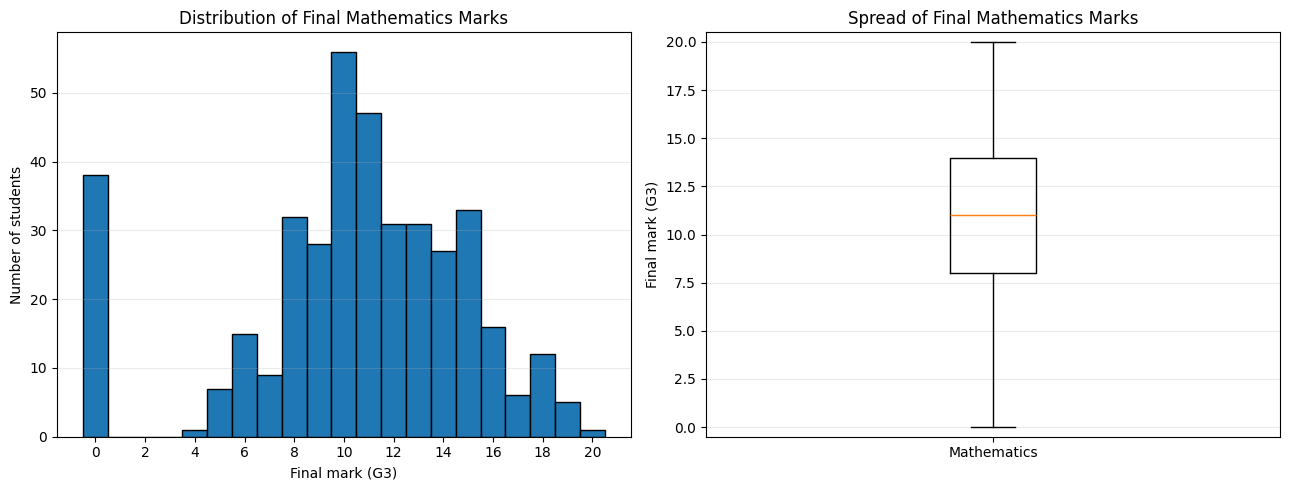

In [3]:
# Target variable: final mathematics grade
target = df["G3_math"]

summary = pd.DataFrame({
    "Value": [
        len(target),
        target.mean(),
        target.median(),
        target.std(),
        target.min(),
        target.max(),
        (target == 0).sum(),
        target.isna().sum()
    ]
}, index=[
    "Number of students",
    "Mean mark",
    "Median mark",
    "Standard deviation",
    "Minimum mark",
    "Maximum mark",
    "Students scoring zero",
    "Missing target values"
])

display(summary.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Histogram
axes[0].hist(
    target,
    bins=np.arange(-0.5, 21.5, 1),
    edgecolor="black"
)
axes[0].set_title("Distribution of Final Mathematics Marks")
axes[0].set_xlabel("Final mark (G3)")
axes[0].set_ylabel("Number of students")
axes[0].set_xticks(range(0, 21, 2))
axes[0].grid(axis="y", alpha=0.25)

# Box plot
axes[1].boxplot(target, tick_labels=["Mathematics"])
axes[1].set_title("Spread of Final Mathematics Marks")
axes[1].set_ylabel("Final mark (G3)")
axes[1].set_ylim(-0.5, 20.5)
axes[1].grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()



,Students,Mean,Median,Std,Min,Max,Zero marks,Zero mark (%)
school__GP,,,,,,,,
MS (Mousinho da Silveira),46,9.85,10.0,4.24,0.0,19.0,4,8.70
GP (Gabriel Pereira),349,10.49,11.0,4.63,0.0,20.0,34,9.74


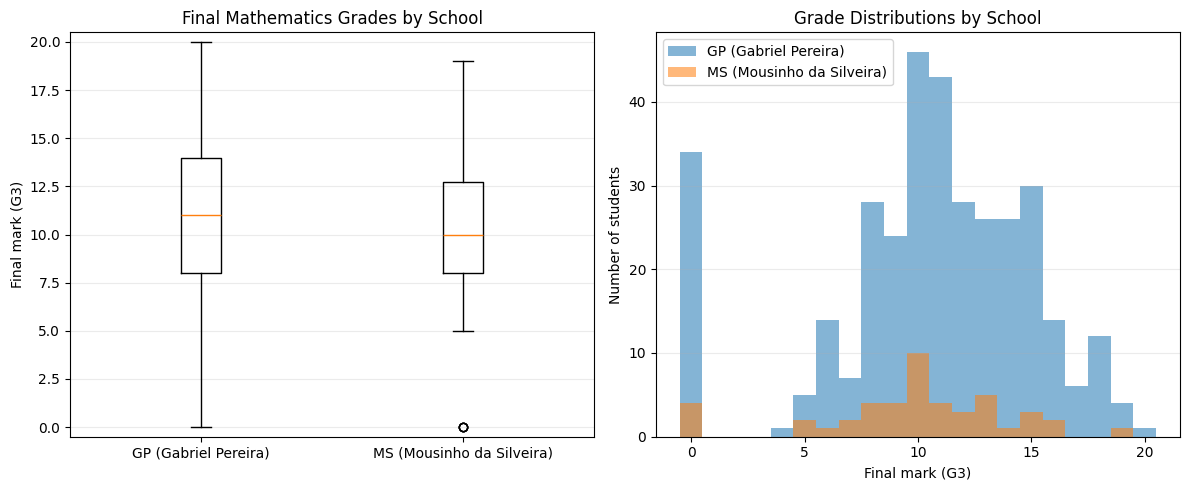

In [4]:
school_summary = (
    df.groupby("school__GP")["G3_math"]
    .agg(
        Students="count",
        Mean="mean",
        Median="median",
        Std="std",
        Min="min",
        Max="max"
    )
)

# Convert the encoded school indicator into readable names
school_summary.index = school_summary.index.map({
    1: "GP (Gabriel Pereira)",
    0: "MS (Mousinho da Silveira)"
})

school_summary["Zero marks"] = (
    df.groupby("school__GP")["G3_math"]
    .apply(lambda x: (x == 0).sum())
    .to_numpy()
)

school_summary["Zero mark (%)"] = (
    school_summary["Zero marks"] / school_summary["Students"] * 100
)

display(school_summary.round(2))

school_labels = {
    1: "GP (Gabriel Pereira)",
    0: "MS (Mousinho da Silveira)"
}

groups = [
    df.loc[df["school__GP"] == code, "G3_math"]
    for code in [1, 0]
]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Box plot
axes[0].boxplot(
    groups,
    tick_labels=[school_labels[1], school_labels[0]]
)
axes[0].set_title("Final Mathematics Grades by School")
axes[0].set_ylabel("Final mark (G3)")
axes[0].set_ylim(-0.5, 20.5)
axes[0].grid(axis="y", alpha=0.25)

# Grade distributions
for code, label in school_labels.items():
    grades = df.loc[df["school__GP"] == code, "G3_math"]
    axes[1].hist(
        grades,
        bins=np.arange(-0.5, 21.5, 1),
        alpha=0.55,
        label=label
    )

axes[1].set_title("Grade Distributions by School")
axes[1].set_xlabel("Final mark (G3)")
axes[1].set_ylabel("Number of students")
axes[1].legend()
axes[1].grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

Pearson correlation matrix:


,G1,G2,G3_math
G1,1.000,0.852,0.801
G2,0.852,1.000,0.905
G3_math,0.801,0.905,1.000



Correlations with final mathematics grade:
G1 vs G3_math: 0.801
G2 vs G3_math: 0.905
G1 vs G2:      0.852


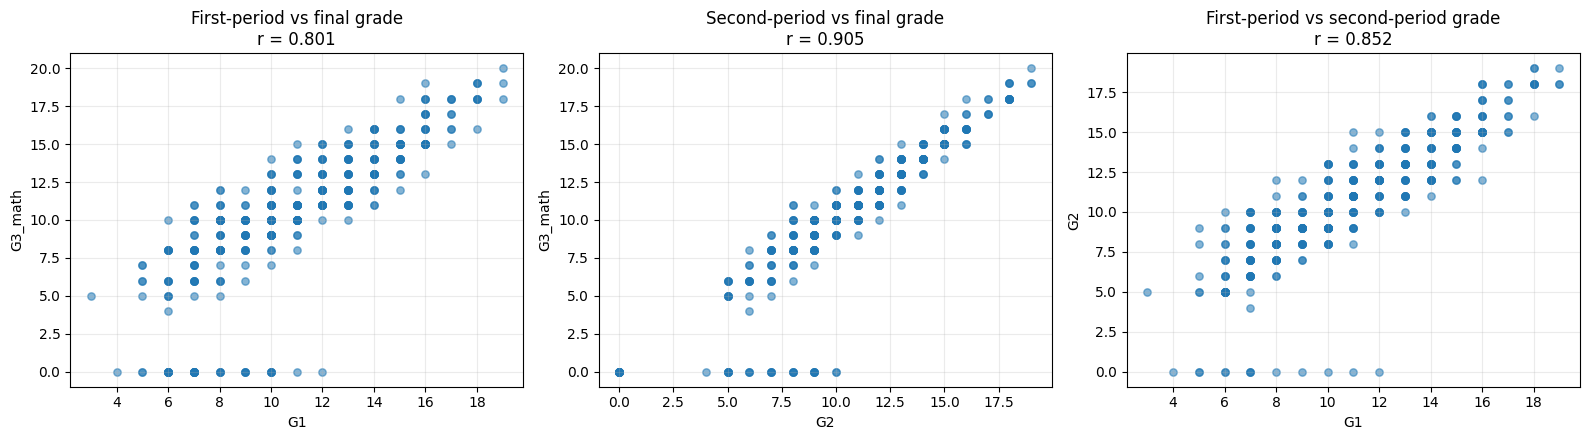

,Students,Mean_final_grade,Median_final_grade
G2,,,
0,13,0.00,0.0
4,1,0.00,0.0
5,15,3.27,5.0
6,14,4.79,6.0
7,21,5.90,7.0
8,32,7.44,8.0
9,50,8.22,9.0
10,46,9.78,10.0
11,35,10.94,11.0


In [5]:
grade_cols = ["G1", "G2", "G3_math"]

grade_corr = df[grade_cols].corr(method="pearson")

print("Pearson correlation matrix:")
display(grade_corr.round(3))

print("\nCorrelations with final mathematics grade:")
print(f"G1 vs G3_math: {grade_corr.loc['G1', 'G3_math']:.3f}")
print(f"G2 vs G3_math: {grade_corr.loc['G2', 'G3_math']:.3f}")
print(f"G1 vs G2:      {grade_corr.loc['G1', 'G2']:.3f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

relationships = [
    ("G1", "G3_math", "First-period vs final grade"),
    ("G2", "G3_math", "Second-period vs final grade"),
    ("G1", "G2", "First-period vs second-period grade")
]

for ax, (x_col, y_col, title) in zip(axes, relationships):
    ax.scatter(
        df[x_col],
        df[y_col],
        alpha=0.55,
        s=28
    )

    corr = df[x_col].corr(df[y_col])

    ax.set_title(f"{title}\nr = {corr:.3f}")
    ax.set_xlabel(x_col)
    ax.set_ylabel(y_col)
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

grade_progression = (
    df.groupby("G2")["G3_math"]
      .agg(
          Students="count",
          Mean_final_grade="mean",
          Median_final_grade="median"
      )
      .sort_index()
)

display(grade_progression.round(2))

Study time category vs final grade


,Students,Mean,Median,Std,Zero_marks
studytime,,,,,
1,105,10.05,10.0,4.96,13
2,198,10.17,11.0,4.22,16
3,65,11.40,12.0,4.64,6
4,27,11.26,12.0,5.28,3


Previous failures vs final grade


,Students,Mean,Median,Std,Zero_marks
failures,,,,,
0,312,11.25,11.0,4.17,18
1,50,8.12,9.0,4.71,10
2,17,6.24,8.0,4.84,5
3,16,5.69,7.0,4.19,5


Absences distribution


,Absences
count,395.000000
mean,5.708861
std,8.003096
min,0.000000
25%,0.000000
50%,4.000000
75%,8.000000
max,75.000000


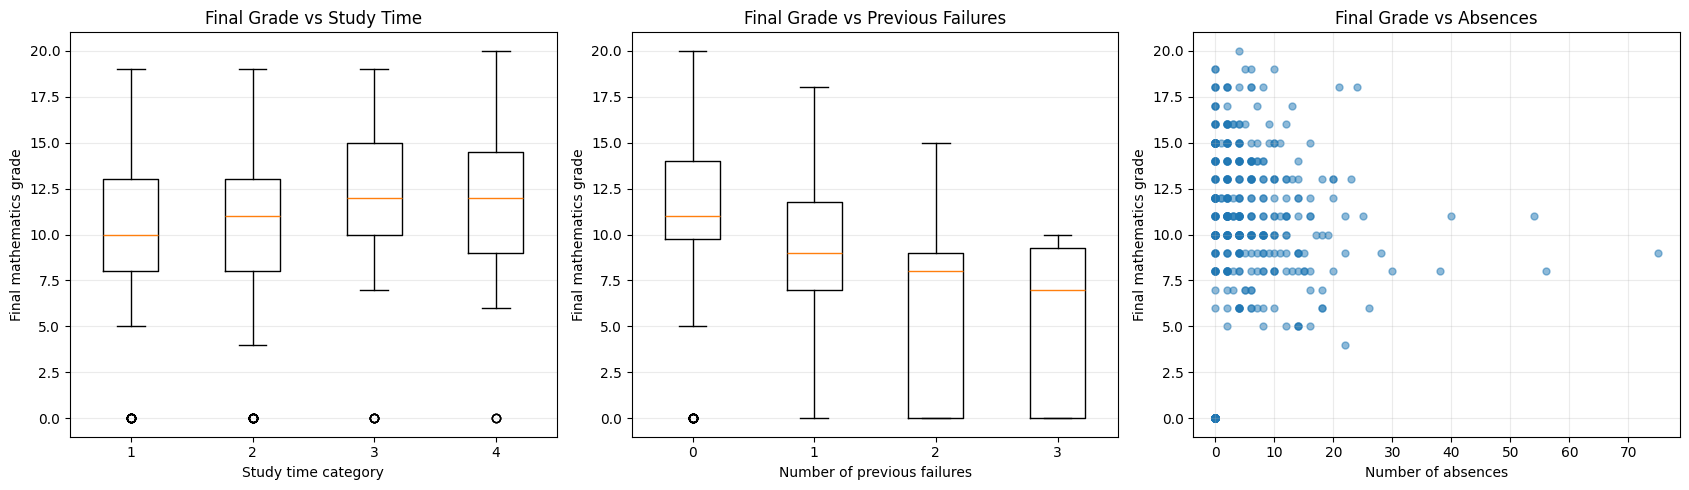

In [6]:
# Study time versus final mathematics grade
study_summary = (
    df.groupby("studytime")["G3_math"]
      .agg(
          Students="count",
          Mean="mean",
          Median="median",
          Std="std"
      )
)

study_summary["Zero_marks"] = (
    df.groupby("studytime")["G3_math"]
      .apply(lambda x: (x == 0).sum())
)

print("Study time category vs final grade")
display(study_summary.round(2))


# Previous failures versus final mathematics grade
failure_summary = (
    df.groupby("failures")["G3_math"]
      .agg(
          Students="count",
          Mean="mean",
          Median="median",
          Std="std"
      )
)

failure_summary["Zero_marks"] = (
    df.groupby("failures")["G3_math"]
      .apply(lambda x: (x == 0).sum())
)

print("Previous failures vs final grade")
display(failure_summary.round(2))


# Absences summary
print("Absences distribution")
display(
    df["absences"].describe().to_frame("Absences")
)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# Study time
study_groups = [
    df.loc[df["studytime"] == value, "G3_math"]
    for value in sorted(df["studytime"].unique())
]

axes[0].boxplot(
    study_groups,
    tick_labels=sorted(df["studytime"].unique())
)
axes[0].set_title("Final Grade vs Study Time")
axes[0].set_xlabel("Study time category")
axes[0].set_ylabel("Final mathematics grade")
axes[0].grid(axis="y", alpha=0.25)


# Previous failures
failure_values = sorted(df["failures"].unique())
failure_groups = [
    df.loc[df["failures"] == value, "G3_math"]
    for value in failure_values
]

axes[1].boxplot(
    failure_groups,
    tick_labels=failure_values
)
axes[1].set_title("Final Grade vs Previous Failures")
axes[1].set_xlabel("Number of previous failures")
axes[1].set_ylabel("Final mathematics grade")
axes[1].grid(axis="y", alpha=0.25)


# Absences
axes[2].scatter(
    df["absences"],
    df["G3_math"],
    alpha=0.5,
    s=25
)
axes[2].set_title("Final Grade vs Absences")
axes[2].set_xlabel("Number of absences")
axes[2].set_ylabel("Final mathematics grade")
axes[2].grid(alpha=0.25)

plt.tight_layout()
plt.show()




,Feature,Category,Students,Mean grade,Median grade,Zero marks
0,Extracurricular activities,No,194,10.34,11.0,17
1,Extracurricular activities,Yes,201,10.49,11.0,21
2,Family support,No,153,10.64,11.0,15
3,Family support,Yes,242,10.27,11.0,23
4,Higher education aspiration,No,20,6.80,8.0,6
5,Higher education aspiration,Yes,375,10.61,11.0,32
6,Internet access,No,66,9.41,10.0,8
7,Internet access,Yes,329,10.62,11.0,30
8,Paid extra classes,No,214,9.99,11.0,30
9,Paid extra classes,Yes,181,10.92,11.0,8


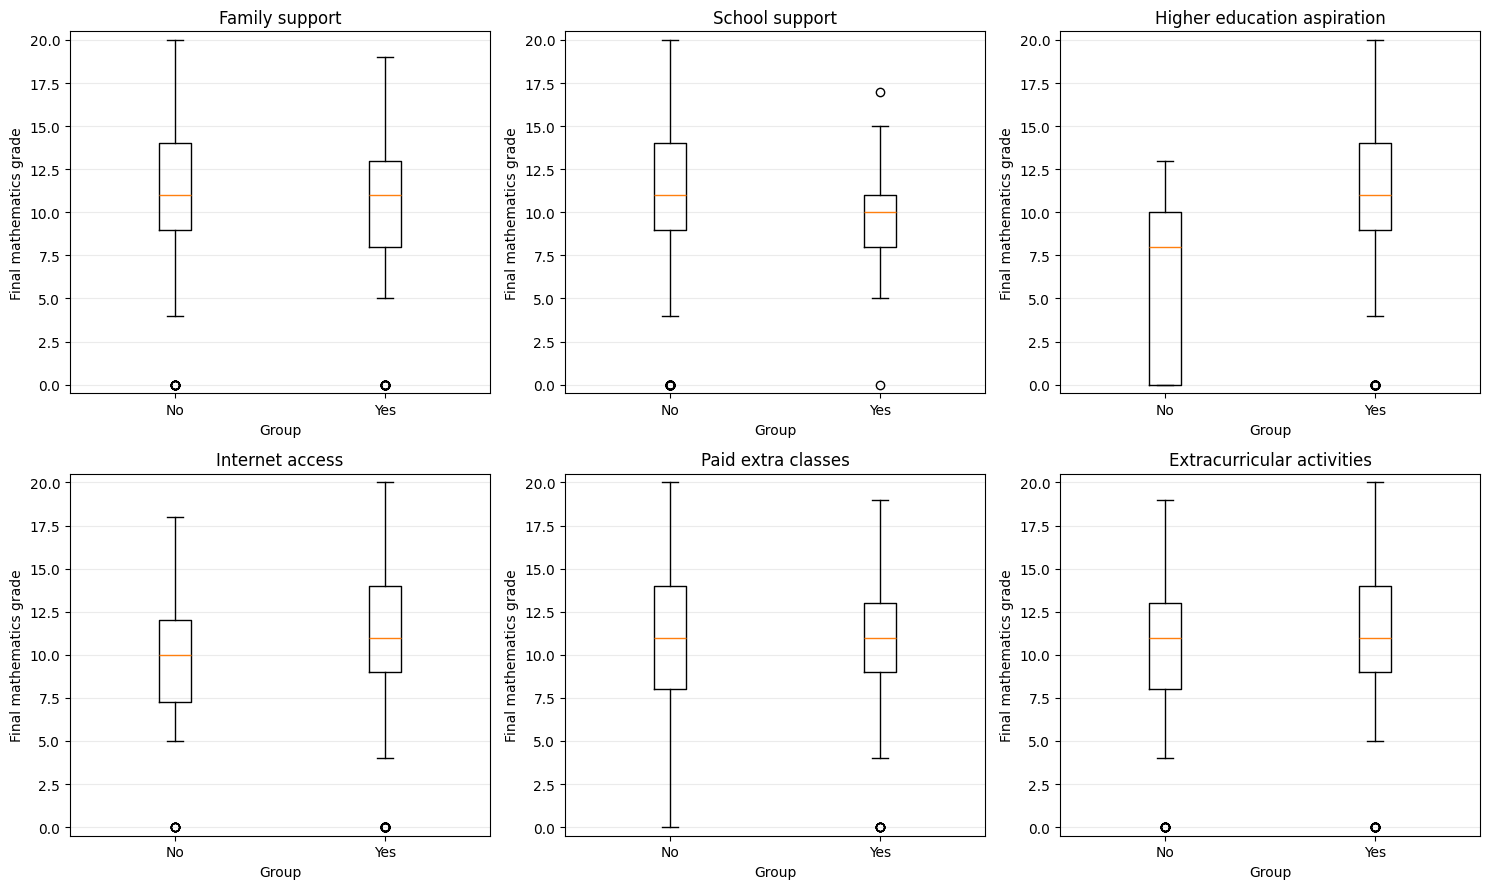

,Students,Mean,Median,Parent,Education level
0,3,13.00,15.0,Mother's education,0
1,59,8.68,10.0,Mother's education,1
2,103,9.73,11.0,Mother's education,2
3,99,10.30,10.0,Mother's education,3
4,131,11.76,12.0,Mother's education,4
5,2,13.00,13.0,Father's education,0
6,82,9.16,10.0,Father's education,1
7,115,10.26,11.0,Father's education,2
8,100,10.66,10.0,Father's education,3
9,96,11.36,12.0,Father's education,4


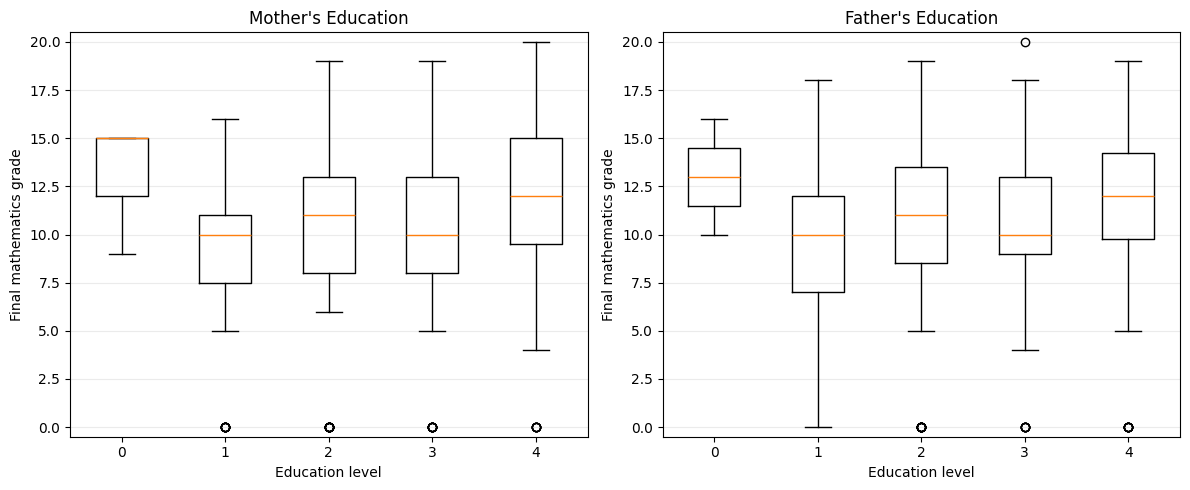

In [7]:
# Features represented by one-hot encoded yes/no columns
binary_features = {
    "Family support": "famsup",
    "School support": "schoolsup",
    "Higher education aspiration": "higher",
    "Internet access": "internet",
    "Paid extra classes": "paid",
    "Extracurricular activities": "activities"
}

summary_tables = []

for label, feature in binary_features.items():
    yes_col = f"{feature}__yes"
    no_col = f"{feature}__no"

    if yes_col not in df.columns or no_col not in df.columns:
        print(f"Skipping {label}: expected encoded columns not found.")
        continue

    for category, indicator in [("Yes", yes_col), ("No", no_col)]:
        subset = df.loc[df[indicator] == 1, "G3_math"]

        summary_tables.append({
            "Feature": label,
            "Category": category,
            "Students": len(subset),
            "Mean grade": subset.mean(),
            "Median grade": subset.median(),
            "Zero marks": (subset == 0).sum()
        })

categorical_summary = pd.DataFrame(summary_tables)

display(
    categorical_summary.round(2)
    .sort_values(["Feature", "Category"])
    .reset_index(drop=True)
)

available_features = [
    (label, feature)
    for label, feature in binary_features.items()
    if f"{feature}__yes" in df.columns
    and f"{feature}__no" in df.columns
]

n = len(available_features)
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for ax, (label, feature) in zip(axes, available_features):
    yes_col = f"{feature}__yes"
    no_col = f"{feature}__no"

    groups = [
        df.loc[df[no_col] == 1, "G3_math"],
        df.loc[df[yes_col] == 1, "G3_math"]
    ]

    ax.boxplot(groups, tick_labels=["No", "Yes"])
    ax.set_title(label)
    ax.set_xlabel("Group")
    ax.set_ylabel("Final mathematics grade")
    ax.set_ylim(-0.5, 20.5)
    ax.grid(axis="y", alpha=0.25)

for ax in axes[n:]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

parent_education = []

for feature, label in [
    ("Medu", "Mother's education"),
    ("Fedu", "Father's education")
]:
    grouped = df.groupby(feature)["G3_math"].agg(
        Students="count",
        Mean="mean",
        Median="median"
    )

    grouped["Parent"] = label
    grouped["Education level"] = grouped.index
    parent_education.append(grouped.reset_index(drop=True))

parent_education_summary = pd.concat(
    parent_education,
    ignore_index=True
)

display(parent_education_summary.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, feature, title in [
    (axes[0], "Medu", "Mother's Education"),
    (axes[1], "Fedu", "Father's Education")
]:
    levels = sorted(df[feature].dropna().unique())
    groups = [
        df.loc[df[feature] == level, "G3_math"]
        for level in levels
    ]

    ax.boxplot(groups, tick_labels=levels)
    ax.set_title(title)
    ax.set_xlabel("Education level")
    ax.set_ylabel("Final mathematics grade")
    ax.set_ylim(-0.5, 20.5)
    ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

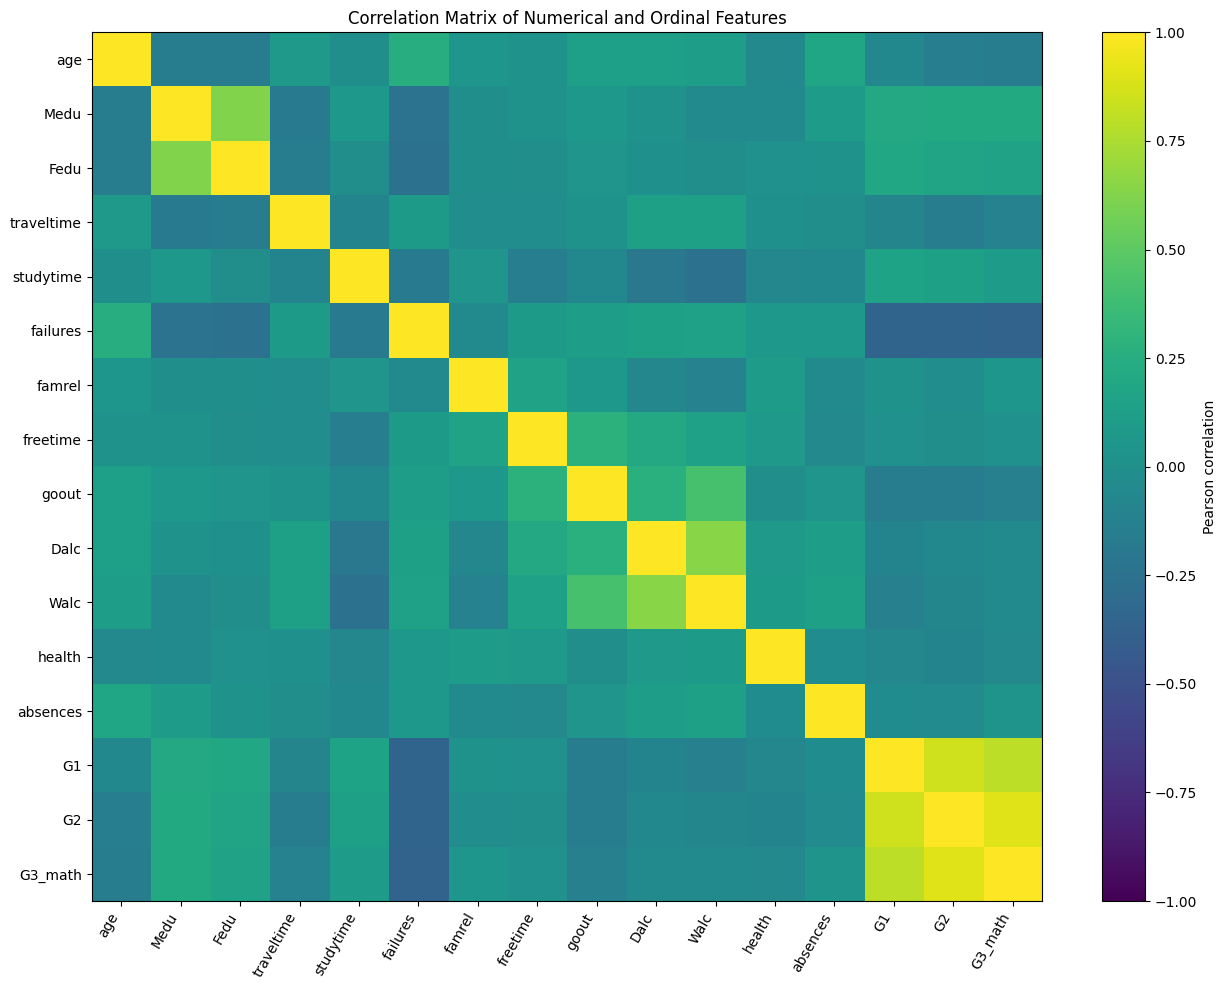

,Feature 1,Feature 2,Correlation,Absolute correlation
119,G2,G3_math,0.905,0.905
117,G1,G2,0.852,0.852
118,G1,G3_math,0.801,0.801
99,Dalc,Walc,0.648,0.648
15,Medu,Fedu,0.623,0.623
93,goout,Walc,0.420,0.420
74,failures,G3_math,-0.360,0.360
73,failures,G2,-0.356,0.356
72,failures,G1,-0.355,0.355
84,freetime,goout,0.285,0.285


Number of mathematics records: 395
Unexpected subjects: ['Mathematics']

Target column checks:


,Missing values
G3_math,0
G3_portuguese,395
G3_target,0



G3_math equals G3_target: True

School indicator checks:


,Number of students
school__GP,349
school__MS,46


Exactly one school indicator per row: True

Input columns with missing values:


,Missing values



Duplicate full rows: 0


In [8]:
# Original numerical and ordinal features
numeric_features = [
    "age", "Medu", "Fedu", "traveltime", "studytime",
    "failures", "famrel", "freetime", "goout",
    "Dalc", "Walc", "health", "absences", "G1", "G2"
]

# Keep only columns that exist in the current dataset
numeric_features = [c for c in numeric_features if c in df.columns]

corr_data = df[numeric_features + ["G3_math"]].corr()

plt.figure(figsize=(13, 10))
plt.imshow(corr_data, aspect="auto", vmin=-1, vmax=1)
plt.colorbar(label="Pearson correlation")

plt.xticks(
    range(len(corr_data.columns)),
    corr_data.columns,
    rotation=60,
    ha="right"
)
plt.yticks(range(len(corr_data.index)), corr_data.index)

plt.title("Correlation Matrix of Numerical and Ordinal Features")
plt.tight_layout()
plt.show()

# Extract unique feature pairs, excluding self-correlations
corr_pairs = (
    corr_data.where(
        np.triu(np.ones(corr_data.shape), k=1).astype(bool)
    )
    .stack()
    .rename("Correlation")
    .reset_index()
)

corr_pairs.columns = ["Feature 1", "Feature 2", "Correlation"]
corr_pairs["Absolute correlation"] = corr_pairs["Correlation"].abs()

display(
    corr_pairs.sort_values(
        "Absolute correlation", ascending=False
    ).head(15).round(3)
)

# Confirm that the mathematics subset is correct
print("Number of mathematics records:", len(df))
print("Unexpected subjects:", df["Subject"].unique())

# Check target columns
target_columns = ["G3_math", "G3_portuguese", "G3_target"]

print("\nTarget column checks:")
display(df[target_columns].isna().sum().to_frame("Missing values"))

# For mathematics rows, the active target columns should agree
print(
    "\nG3_math equals G3_target:",
    np.allclose(df["G3_math"], df["G3_target"], equal_nan=True)
)

# Check one-hot school indicators
school_cols = ["school__GP", "school__MS"]

print("\nSchool indicator checks:")
display(df[school_cols].sum().to_frame("Number of students"))

print(
    "Exactly one school indicator per row:",
    (df[school_cols].sum(axis=1) == 1).all()
)

# Check missing values in the potential input features
excluded = ["Subject", "G3_math", "G3_portuguese", "G3_target"]
input_candidates = [c for c in df.columns if c not in excluded]

missing = df[input_candidates].isna().sum()
print("\nInput columns with missing values:")
display(missing[missing > 0].to_frame("Missing values"))

print("\nDuplicate full rows:", df.duplicated().sum())